# QBUS3340 Task 3: Joint Optimisation
Costs are in AUD, preforms in units, quartz in metric tonnes, and helium in m³.


## 3(a) Joint model formulation — 10 marks

### Sets, parameters and units

Production days are $t\in T=\{1,\ldots,20\}$; helium placement days are $s\in S=\{0,\ldots,19\}$. The known demand on day $t$ is $d_t$.

| Parameter | Value | Unit / meaning |
|:--|--:|:--|
| Setup cost $K$ | 1,000 | AUD per batch; at most one batch each day |
| Variable production cost $c$ | 10 | AUD per preform produced |
| Finished holding cost $h$ | 15 | AUD per preform per day |
| Backorder cost $b$ | 100 | AUD per outstanding preform per day |
| Batch capacity $M$ | 100 | Preforms per day |
| Quartz consumption $a_Q$ | 0.08 | Tonnes/preform = 80 kg / 1,000 |
| Helium consumption $a_G$ | 2 | m³/preform |
| Quartz procurement $p_Q$ | 350 | AUD/tonne |
| Helium procurement $p_G$ | 500 | AUD/m³ |
| Quartz holding $h_Q$ | 0.50 | AUD/tonne/day |
| Helium holding $h_G$ | 1 | AUD/m³/day |
| Quartz conversion $v_Q$ | 3.50 | AUD per preform produced |
| Helium conversion $v_G$ | 5.00 | AUD per preform produced |
| Initial finished stock $I_0$ | 20 | Preforms |
| Initial quartz stock $Q_0$ | 5 | Tonnes |
| Initial helium stock $G_0$ | 160 | m³ |
| Initial backorders $B_0$ | 0 | Preforms |

### Decision variables

| Variable | Definition | Domain |
|:--|:--|:--|
| $x_t$ | Preforms produced on day $t$ | Non-negative integer |
| $y_t$ | 1 if a batch is started on day $t$; 0 otherwise | Binary |
| $I_t, B_t$ | End-of-day finished inventory and backorders | Non-negative integers |
| $q$ | Same quartz delivery every morning, days 1–20 | Non-negative continuous, tonnes/day |
| $Q_t$ | End-of-day quartz inventory | Non-negative continuous, tonnes |
| $H_s$ | Helium placed on day $s$, arriving on day $s+1$ | Non-negative continuous, m³ |
| $G_t$ | End-of-day helium inventory | Non-negative continuous, m³ |

### Objective: minimise the full 20-day cost

$$
\begin{aligned}
\min C ={}& \sum_{t=1}^{20}\left(1000y_t+10x_t+15I_t+100B_t\right)\\
&+ 20(350)q + 500\sum_{s=0}^{19}H_s\\
&+ \sum_{t=1}^{20}\left(0.50Q_t+1.00G_t\right)\\
&+ (3.50+5.00)\sum_{t=1}^{20}x_t.
\end{aligned}
$$

| Objective term | Cost represented |
|:--|:--|
| $1000\sum y_t$ | Batch setups |
| $10\sum x_t$ | Variable production |
| $15\sum I_t$ | Finished-preform holding |
| $100\sum B_t$ | Backorders |
| $20(350)q$ | All 20 quartz deliveries |
| $500\sum H_s$ | New helium purchases |
| $0.50\sum Q_t+1.00\sum G_t$ | End-of-day input holding |
| $(3.50+5.00)\sum x_t$ | Quartz and helium conversion, counted once |

In words: minimise setups + variable production + finished holding + backorders + input procurement + input holding + conversion. Task 1 includes only the first four terms. The remaining terms enter in Tasks 2–3. Initial stocks are already available, so they are not purchased again, only production during the horizon incurs conversion charges.

### Constraints and timing

**1. One batch per day and capacity**

$$
0\le x_t\le100y_t,\qquad t=1,\ldots,20.
$$

A binary setup permits at most one batch and at most 100 preforms on a day. Positive setup cost prevents an unnecessary setup with zero production at an optimum.

**2. Finished inventory and backorder balance**

$$
I_t-B_t=I_{t-1}-B_{t-1}+x_t-d_t,\qquad t=1,\ldots,20.
$$

Today's production is available for today's demand. Unmet orders carry forward through $B_t$; finished stock and backorders are charged at the end of each day.

**3. Quartz balance with the same morning delivery every day**

$$
Q_t=Q_{t-1}+q-0.08x_t,\qquad t=1,\ldots,20.
$$

One scalar $q$ enforces the constant-delivery rule. Each morning's delivery can be used that day; $Q_t\ge0$ prevents consumption without available quartz.

**4. Helium balance with a 24-hour lead time**

$$
G_t=G_{t-1}+H_{t-1}-2x_t,\qquad t=1,\ldots,20.
$$

$H_0$ is a new order placed on the morning of day 0 and arriving before day-1 production. There is no inventory in transit before this order. $H_{19}$ arrives on day 20. A day-20 order is omitted because it would arrive after the horizon. $G_t\ge0$ prevents helium shortages.

**5. Initial and terminal conditions**

$$
I_0=20,\quad B_0=0,\quad Q_0=5,\quad G_0=160,\qquad B_{20}=0.
$$

1. All backorders must be cleared by day 20.
2. Ending inventories may be positive and have no salvage value. 

In [1]:
from pathlib import Path
from io import StringIO
from time import perf_counter
import json
import platform
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
from IPython.display import display, Markdown

DATA_FILE = Path("ZORA_synthetic_demand_data.xlsx")
BASELINE_FILE = Path("part1-2.ipynb")
OUT = Path("task3_outputs")
OUT.mkdir(exist_ok=True)
if not DATA_FILE.exists():
    raise FileNotFoundError("Open this notebook from the folder containing the demand workbook.")

conf = pd.read_excel(DATA_FILE, sheet_name="Confirmed_20_Day_Demand").sort_values("planning_day")
DAYS = list(range(1, 21))
ORDER_DAYS = list(range(20))
assert conf["planning_day"].tolist() == DAYS, "Expected exactly planning days 1–20."
raw_demand = conf["confirmed_demand_preforms"].to_numpy(dtype=float)
assert np.isfinite(raw_demand).all() and (raw_demand >= 0).all()
assert np.allclose(raw_demand, np.round(raw_demand)), "Preform demand must be integer."
demand = dict(zip(DAYS, raw_demand.astype(int)))

K, c, h, b, M = 1000, 10, 15, 100, 100
I0, B0, Q0, G0 = 20, 0, 5.0, 160.0
aQ, aG, pQ, pG, hQ, hG, vQ, vG = 0.08, 2.0, 350, 500, 0.50, 1.0, 3.50, 5.00
PRODUCTION_KEYS = ["Setup", "Variable production", "Finished holding", "Backorder"]
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
SEQ_COLOR, JOINT_COLOR = "#a45b37", "#246b9b"


def show_table(frame, decimals=2, money=False):
    numeric = frame.select_dtypes(include="number").columns
    formats = {col: ("{:,.0f}" if pd.api.types.is_integer_dtype(frame[col])
                     else "{:,." + str(decimals) + "f}") for col in numeric}
    if money:
        formats = {col: "{:,.2f}" for col in numeric}
    display(frame.style.format(formats).hide(axis="index"))

print(f"Python {platform.python_version()} | PuLP {pulp.__version__} | pandas {pd.__version__}")
print(f"Confirmed demand: {sum(demand.values()):,} preforms over {len(DAYS)} days")
print("Quartz consumption: 80 kg / 1,000 = 0.08 tonnes per preform")
show_table(conf[["planning_day", "date", "confirmed_demand_preforms"]].rename(
    columns={"planning_day":"Day", "date":"Date", "confirmed_demand_preforms":"Demand"}))

Python 3.12.13 | PuLP 3.3.0 | pandas 3.0.6
Confirmed demand: 1,157 preforms over 20 days
Quartz consumption: 80 kg / 1,000 = 0.08 tonnes per preform


Day,Date,Demand
1,2026-08-03 00:00:00,56
2,2026-08-04 00:00:00,55
3,2026-08-05 00:00:00,54
4,2026-08-06 00:00:00,39
5,2026-08-07 00:00:00,56
6,2026-08-08 00:00:00,58
7,2026-08-09 00:00:00,61
8,2026-08-10 00:00:00,72
9,2026-08-11 00:00:00,64
10,2026-08-12 00:00:00,62


## 3(b) Solve and report the joint optimum — 8 marks

The following functions implement the formulation above. Production variables and constraints are shared with the sequential Task 1 verification; input variables and constraints are shared with Task 2. CBC solves with zero requested relative/absolute optimality gap. The notebook checks both solver status and solution status before reporting an optimum and retains the solver logs for inspection.

In [2]:
def production_block(model):
    x = pulp.LpVariable.dicts("x", DAYS, lowBound=0, cat="Integer")
    y = pulp.LpVariable.dicts("y", DAYS, cat="Binary")
    I = pulp.LpVariable.dicts("I", [0] + DAYS, lowBound=0, cat="Integer")
    B = pulp.LpVariable.dicts("B", [0] + DAYS, lowBound=0, cat="Integer")
    model += I[0] == I0, "initial_finished"
    model += B[0] == B0, "initial_backorders"
    for t in DAYS:
        model += x[t] <= M * y[t], f"batch_capacity_{t}"
        model += I[t] - B[t] == I[t-1] - B[t-1] + x[t] - demand[t], f"finished_balance_{t}"
    model += B[20] == 0, "all_orders_fulfilled"
    terms = {
        "Setup": K * pulp.lpSum(y.values()),
        "Variable production": c * pulp.lpSum(x.values()),
        "Finished holding": h * pulp.lpSum(I[t] for t in DAYS),
        "Backorder": b * pulp.lpSum(B[t] for t in DAYS),
    }
    return {"x": x, "y": y, "I": I, "B": B}, terms


def supply_block(model, production):
    q = pulp.LpVariable("constant_quartz_t_per_day", lowBound=0)
    Q = pulp.LpVariable.dicts("Q", [0] + DAYS, lowBound=0)
    H = pulp.LpVariable.dicts("H", ORDER_DAYS, lowBound=0)
    G = pulp.LpVariable.dicts("G", [0] + DAYS, lowBound=0)
    model += Q[0] == Q0, "initial_quartz"
    model += G[0] == G0, "initial_helium"
    for t in DAYS:
        model += Q[t] == Q[t-1] + q - aQ * production[t], f"quartz_balance_{t}"
        model += G[t] == G[t-1] + H[t-1] - aG * production[t], f"helium_balance_{t}"
    terms = {
        "Quartz procurement": len(DAYS) * pQ * q,
        "Helium procurement": pG * pulp.lpSum(H.values()),
        "Quartz holding": hQ * pulp.lpSum(Q[t] for t in DAYS),
        "Helium holding": hG * pulp.lpSum(G[t] for t in DAYS),
        "Quartz conversion": vQ * pulp.lpSum(production.values()),
        "Helium conversion": vG * pulp.lpSum(production.values()),
    }
    return {"q": q, "Q": Q, "H": H, "G": G}, terms


def solve_model(model, label):
    logfile = OUT / f"{label}_cbc.log"
    solver = pulp.PULP_CBC_CMD(msg=False, gapRel=0, gapAbs=0, threads=1, logPath=str(logfile))
    if not solver.available():
        raise RuntimeError("CBC is unavailable. Install PuLP with its bundled CBC solver.")
    start = perf_counter()
    model.solve(solver)
    elapsed = perf_counter() - start
    if model.status != pulp.LpStatusOptimal or model.sol_status != pulp.LpSolutionOptimal:
        raise RuntimeError(f"{label}: no certified optimum; {pulp.LpStatus[model.status]}")
    return {"Model": label, "Status": pulp.LpStatus[model.status],
            "Variables": len(model.variables()), "Constraints": len(model.constraints),
            "Seconds": elapsed, "Objective (AUD)": pulp.value(model.objective)}


def production_table(v):
    return pd.DataFrame({"Day": DAYS, "Demand": [demand[t] for t in DAYS],
        "Production": [int(round(v["x"][t].value())) for t in DAYS],
        "Setup": [int(round(v["y"][t].value())) for t in DAYS],
        "Finished end": [v["I"][t].value() for t in DAYS],
        "Backorders end": [v["B"][t].value() for t in DAYS]})


def attach_supply(plan, v):
    plan = plan.copy()
    plan["Quartz use (t)"] = aQ * plan["Production"]
    plan["Quartz delivery (t)"] = v["q"].value()
    plan["Quartz end (t)"] = [v["Q"][t].value() for t in DAYS]
    plan["Helium use (m3)"] = aG * plan["Production"]
    plan["Helium arrival (m3)"] = [v["H"][t-1].value() for t in DAYS]
    plan["Helium end (m3)"] = [v["G"][t].value() for t in DAYS]
    return plan


joint_model = pulp.LpProblem("Task3_joint", pulp.LpMinimize)
joint_prod, joint_production_terms = production_block(joint_model)
joint_supply, joint_supply_terms = supply_block(joint_model, joint_prod["x"])
joint_terms = {**joint_production_terms, **joint_supply_terms}
joint_model += pulp.lpSum(joint_terms.values())
joint_run = solve_model(joint_model, "joint")
joint_plan = attach_supply(production_table(joint_prod), joint_supply)
joint_costs = {name: pulp.value(term) for name, term in joint_terms.items()}
joint_total = sum(joint_costs.values())
show_table(pd.DataFrame([joint_run]))
print(f"Joint cost: AUD {joint_total:,.2f}; quartz delivery: {joint_supply['q'].value():.6f} tonnes/day")

Model,Status,Variables,Constraints,Seconds,Objective (AUD)
joint,Optimal,145,85,0.90,"1,127,637.48"


Joint cost: AUD 1,127,637.48; quartz delivery: 4.308889 tonnes/day


### Daily production, setups and finished balances

All quantities below are preforms except the binary setup indicator. An inventory of 55 at the end of Day 1 supplies Day 2; an inventory of 39 at the end of Day 3 supplies Day 4.

In [3]:
show_table(joint_plan[["Day", "Demand", "Production", "Setup", "Finished end", "Backorders end"]], decimals=0)
print("Setup days:", joint_plan.loc[joint_plan["Setup"] == 1, "Day"].tolist())

Day,Demand,Production,Setup,Finished end,Backorders end
1,56,91,1,55,0
2,55,0,0,0,0
3,54,93,1,39,0
4,39,0,0,0,0
5,56,56,1,0,0
6,58,58,1,0,0
7,61,61,1,0,0
8,72,72,1,0,0
9,64,64,1,0,0
10,62,62,1,0,0


Setup days: [1, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


### Daily quartz deliveries and inventory

The same quantity arrives before production every day, including days with no production. Deliveries continue through Day 20; unused terminal stock receives no salvage credit.

In [4]:
show_table(joint_plan[["Day", "Production", "Quartz use (t)", "Quartz delivery (t)", "Quartz end (t)"]], decimals=6)

Day,Production,Quartz use (t),Quartz delivery (t),Quartz end (t)
1,91,7.280000,4.308889,2.028889
2,0,0.000000,4.308889,6.337778
3,93,7.440000,4.308889,3.206667
4,0,0.000000,4.308889,7.515556
5,56,4.480000,4.308889,7.344444
6,58,4.640000,4.308889,7.013333
7,61,4.880000,4.308889,6.442222
8,72,5.760000,4.308889,4.991111
9,64,5.120000,4.308889,4.180000
10,62,4.960000,4.308889,3.528889


### Helium orders, arrival dates and inventory

Each row pairs an order with its arrival the following morning. The day-0 order supplements initial helium for day-1 production. A zero quantity means no purchase on that placement day. End stock is measured on the **arrival day**.

In [5]:
joint_orders = pd.DataFrame({
    "Placed day": ORDER_DAYS, "Arrival day": DAYS,
    "Order / arrival (m3)": [joint_supply["H"][s].value() for s in ORDER_DAYS],
    "Use on arrival day (m3)": joint_plan["Helium use (m3)"],
    "End stock on arrival day (m3)": joint_plan["Helium end (m3)"]})
show_table(joint_orders, decimals=0)

Placed day,Arrival day,Order / arrival (m3),Use on arrival day (m3),End stock on arrival day (m3)
0,1,22,182,0
1,2,0,0,0
2,3,186,186,0
3,4,0,0,0
4,5,112,112,0
5,6,116,116,0
6,7,122,122,0
7,8,144,144,0
8,9,128,128,0
9,10,124,124,0


### Full cost breakdown

Procurement and conversion are separate costs. Initial inventory is not purchased again. All rows are computed from the same expressions used in the objective; totals and differences use unrounded values.

In [6]:
joint_cost_table = pd.DataFrame({"Cost component": list(joint_costs), "Joint (AUD)": list(joint_costs.values())})
joint_cost_table.loc[len(joint_cost_table)] = ["TOTAL", joint_total]
show_table(joint_cost_table, money=True)

Cost component,Joint (AUD)
Setup,"18,000.00"
Variable production,"11,370.00"
Finished holding,"1,410.00"
Backorder,0.00
Quartz procurement,"30,162.22"
Helium procurement,"1,057,000.00"
Quartz holding,30.75
Helium holding,0.00
Quartz conversion,"3,979.50"
Helium conversion,"5,685.00"


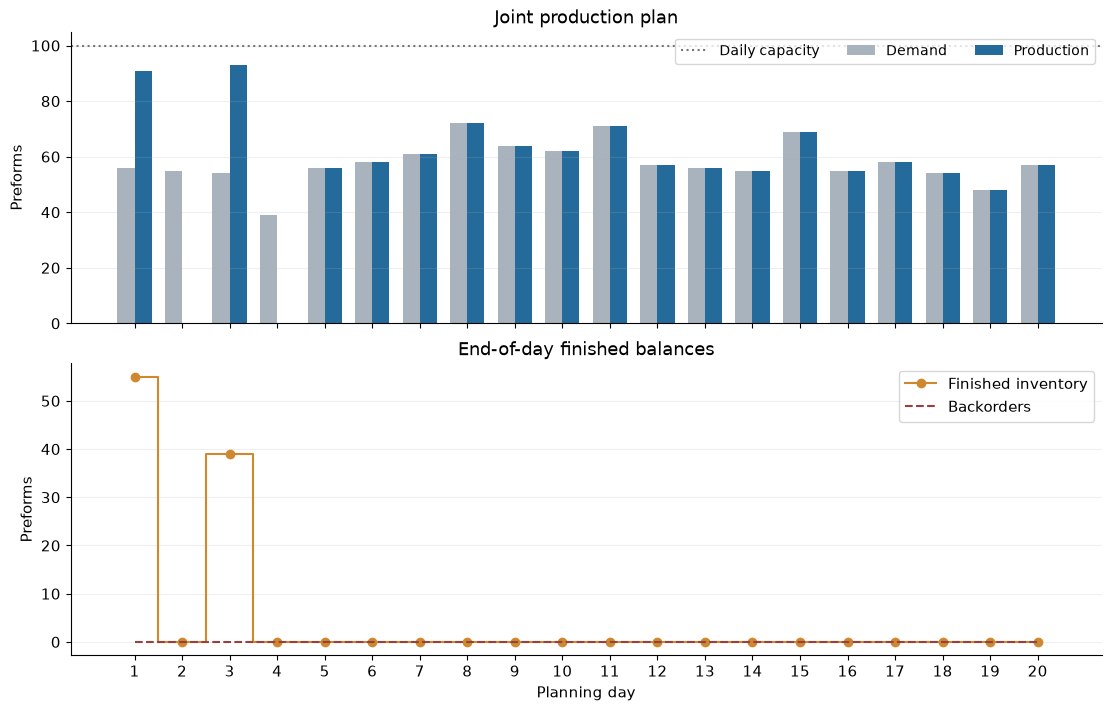

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout="constrained")
d = np.array(DAYS)
ax[0].bar(d - .18, joint_plan["Demand"], .36, label="Demand", color="#a9b3bd")
ax[0].bar(d + .18, joint_plan["Production"], .36, label="Production", color=JOINT_COLOR)
ax[0].axhline(M, color="#777777", linestyle=":", label="Daily capacity")
ax[0].set(ylabel="Preforms", title="Joint production plan")
ax[0].legend(ncol=3, fontsize=10)
ax[1].step(d, joint_plan["Finished end"], where="mid", marker="o", color="#d08830", label="Finished inventory")
ax[1].plot(d, joint_plan["Backorders end"], "--", color="#94423f", label="Backorders")
ax[1].set(xlabel="Planning day", ylabel="Preforms", title="End-of-day finished balances", xticks=DAYS)
ax[1].legend()
for a in ax:
    a.grid(axis="y", alpha=.2)
fig.savefig(OUT / "joint_production.png", dpi=180, bbox_inches="tight")
plt.show()

### Interpretation of the joint optimum

The joint optimum costs **AUD 1,127,637.48**. It produces **1,137 preforms** to meet **1,157 units of demand** after using the initial 20 finished units. Setups occur on **Days 1, 3 and 5–20 (18 batches)**. Production matches demand from Day 5 onward; early batches cover Days 2 and 4 without opening a batch on those days. There are **no backorders on any day** and no final finished stock.

Quartz deliveries are **4.308889 tonnes/day**, or **86.177778 tonnes** over the horizon. With 5 tonnes initially and consumption of **90.96 tonnes**, final quartz stock is **0.217778 tonnes**. This positive remainder is a consequence of the constant-delivery rule, not a failure to minimise procurement.

Helium consumption is **2,274 m³**. Initial stock provides 160 m³, so purchases total **2,114 m³**. The first order is **22 m³ on day 0**, arriving on day 1: $160+22=2(91)$. Subsequent orders arrive just in time for production, leaving zero end-of-day helium inventory. With no ordering fee, no specified supply limit and positive holding cost, earlier helium arrivals offer no benefit under the deterministic assumptions.

Variable production and conversion depend on the total units produced and are identical for the two solutions reported below. Their positive unit rates affect the total cost level; the observed timing trade-off is driven by setups, finished holding and the quartz delivery requirement.

## 3(c) Compare with Tasks 1–2 — 8 marks

### Establish the exact sequential benchmark

Task 2 minimises input costs while holding this production schedule fixed. The sequential full cost is Task 1 cost plus Task 2 cost, with each cost counted once. The comparison therefore uses the same demand, initial stocks, unit costs, lead time, delivery rules and terminal conditions.

In [3]:
baseline_csv = """Day,Demand,Setup,Production,Finished end,Backorders end
1,56,1,91,55,0
2,55,0,0,0,0
3,54,1,93,39,0
4,39,0,0,0,0
5,56,1,56,0,0
6,58,1,58,0,0
7,61,1,61,0,0
8,72,1,72,0,0
9,64,1,64,0,0
10,62,1,62,0,0
11,71,1,71,0,0
12,57,1,68,11,0
13,56,1,100,55,0
14,55,0,0,0,0
15,69,1,69,0,0
16,55,1,55,0,0
17,58,1,60,2,0
18,54,1,100,48,0
19,48,0,0,0,0
20,57,1,57,0,0
"""
baseline = pd.read_csv(StringIO(baseline_csv))
assert baseline["Demand"].tolist() == [demand[t] for t in DAYS], "Workbook differs from the benchmark demand."
if BASELINE_FILE.exists():
    stored_notebook = json.loads(BASELINE_FILE.read_text())
    source_plan = None
    for cell in stored_notebook["cells"]:
        for output in cell.get("outputs", []):
            text = output.get("text", "")
            text = "".join(text) if isinstance(text, list) else text
            match = re.search(r"(?m)^\s*day\s+demand\s+setup\s+production\s+end_inventory\s+end_backorder\s*$", text)
            if match:
                rows = text[match.start():].strip().splitlines()[:21]
                source_plan = pd.read_csv(StringIO("\n".join(rows)), sep=r"\s+")
                break
        if source_plan is not None:
            break
    if source_plan is None:
        raise ValueError("part1-2.ipynb has no saved Task 1 table; run its Task 1 cells and save it.")
    pd.testing.assert_frame_equal(source_plan.set_axis(baseline.columns, axis=1), baseline, check_dtype=False)
    print("Benchmark matches the saved Task 1 table in part1-2.ipynb exactly.")
else:
    print("Using the embedded source snapshot; part1-2.ipynb is not present for the optional source check.")

# Verify the source schedule's cost against a fresh production-only optimum.
task1_model = pulp.LpProblem("Task1_production_verification", pulp.LpMinimize)
task1_vars, task1_terms = production_block(task1_model)
task1_model += pulp.lpSum(task1_terms.values())
task1_run = solve_model(task1_model, "task1")
seq_production_costs = {
    "Setup": K * baseline["Setup"].sum(),
    "Variable production": c * baseline["Production"].sum(),
    "Finished holding": h * baseline["Finished end"].sum(),
    "Backorder": b * baseline["Backorders end"].sum(),
}
task1_total = sum(seq_production_costs.values())
assert abs(task1_total - pulp.value(task1_model.objective)) < 0.001

fixed_x = dict(zip(DAYS, baseline["Production"].astype(int)))
task2_model = pulp.LpProblem("Task2_fixed_production_supply", pulp.LpMinimize)
seq_supply, seq_supply_terms = supply_block(task2_model, fixed_x)
task2_model += pulp.lpSum(seq_supply_terms.values())
task2_run = solve_model(task2_model, "task2")
seq_plan = attach_supply(baseline, seq_supply)
seq_costs = {**seq_production_costs, **{k: pulp.value(v) for k, v in seq_supply_terms.items()}}
seq_total = sum(seq_costs.values())
saving = seq_total - joint_total
print(f"Task 1 cost: AUD {task1_total:,.2f}")
print(f"Task 2 input cost: AUD {pulp.value(task2_model.objective):,.2f}")
print(f"Sequential total: AUD {seq_total:,.2f}")
print(f"Joint total: AUD {joint_total:,.2f}")
print(f"Joint saving: AUD {saving:,.2f} ({100*saving/seq_total:.4f}%)")

Benchmark matches the saved Task 1 table in part1-2.ipynb exactly.
Task 1 cost: AUD 30,520.00
Task 2 input cost: AUD 1,098,368.57
Sequential total: AUD 1,128,888.57
Joint total: AUD 1,127,637.48
Joint saving: AUD 1,251.09 (0.1108%)


### Cost comparison

Positive values in the final column are savings from using the joint model. Negative values are extra joint cost. For example, the quartz procurement saving is calculated before rounding: AUD 1,493.33; subtracting two rounded displayed procurement values can differ by one cent.

In [4]:
comparison = pd.DataFrame({"Sequential (AUD)": seq_costs, "Joint (AUD)": joint_costs})
comparison["Saving: sequential - joint (AUD)"] = comparison["Sequential (AUD)"] - comparison["Joint (AUD)"]
comparison.loc["TOTAL"] = comparison.sum()
show_table(comparison.rename_axis("Cost component").reset_index(), money=True)

Cost component,Sequential (AUD),Joint (AUD),Saving: sequential - joint (AUD)
Setup,"16,000.00","18,000.00","-2,000.00"
Variable production,"11,370.00","11,370.00",0.00
Finished holding,"3,150.00","1,410.00","1,740.00"
Backorder,0.00,0.00,0.00
Quartz procurement,"31,655.56","30,162.22","1,493.33"
Helium procurement,"1,057,000.00","1,057,000.00",0.00
Quartz holding,48.51,30.75,17.76
Helium holding,0.00,0.00,0.00
Quartz conversion,"3,979.50","3,979.50",0.00
Helium conversion,"5,685.00","5,685.00",0.00


In [5]:
def measures(plan):
    return [plan["Production"].sum(), plan["Setup"].sum(), plan["Finished end"].sum(),
            plan["Finished end"].mean(), plan["Finished end"].max(), plan["Backorders end"].sum(),
            plan["Quartz delivery (t)"].iloc[0], plan["Quartz delivery (t)"].sum(),
            plan["Quartz end (t)"].sum(), plan["Quartz end (t)"].iloc[-1],
            plan["Helium arrival (m3)"].sum(), plan["Helium end (m3)"].sum(),
            plan["Finished end"].iloc[-1]]

measure_names = ["Total production", "Setups", "Cumulative finished inventory", "Average finished inventory",
                 "Peak finished inventory", "Cumulative backorders", "Daily quartz delivery", "Total quartz purchased",
                 "Cumulative quartz inventory", "Final quartz inventory", "Total helium purchased",
                 "Cumulative helium inventory", "Final finished inventory"]
units = ["preforms", "batches", "preform-days", "preforms", "preforms", "preform-days", "tonnes/day", "tonnes",
         "tonne-days", "tonnes", "m³", "m³-days", "preforms"]
operating = pd.DataFrame({"Measure": measure_names, "Unit": units,
                          "Sequential": measures(seq_plan), "Joint": measures(joint_plan)})
show_table(operating, decimals=6)

Measure,Unit,Sequential,Joint
Total production,preforms,"1,137.000000","1,137.000000"
Setups,batches,16.000000,18.000000
Cumulative finished inventory,preform-days,210.000000,94.000000
Average finished inventory,preforms,10.500000,4.700000
Peak finished inventory,preforms,55.000000,55.000000
Cumulative backorders,preform-days,0.000000,0.000000
Daily quartz delivery,tonnes/day,4.522222,4.308889
Total quartz purchased,tonnes,90.444444,86.177778
Cumulative quartz inventory,tonne-days,97.026667,61.506667
Final quartz inventory,tonnes,4.484444,0.217778


### Day-by-day production and finished inventory

The table reports every day, including unchanged days. Backorders are zero throughout both plans. The smaller tables below isolate changed production days and changed helium orders; order placement precedes arrival by one day.

In [6]:
daily_comparison = pd.DataFrame({"Day": DAYS, "Demand": seq_plan["Demand"],
    "Production: seq": seq_plan["Production"], "Production: joint": joint_plan["Production"],
    "Finished end: seq": seq_plan["Finished end"], "Finished end: joint": joint_plan["Finished end"],
    "Backorders: seq": seq_plan["Backorders end"], "Backorders: joint": joint_plan["Backorders end"]})
show_table(daily_comparison, decimals=0)
changed = seq_plan["Production"] != joint_plan["Production"]
production_changes = daily_comparison.loc[changed, ["Day", "Production: seq", "Production: joint"]].copy()
production_changes["Joint - seq"] = production_changes["Production: joint"] - production_changes["Production: seq"]
show_table(production_changes, decimals=0)
helium_changes = pd.DataFrame({"Placed day": ORDER_DAYS, "Arrival day": DAYS,
    "Sequential order (m3)": seq_plan["Helium arrival (m3)"], "Joint order (m3)": joint_plan["Helium arrival (m3)"]})
show_table(helium_changes.loc[changed], decimals=0)

Day,Demand,Production: seq,Production: joint,Finished end: seq,Finished end: joint,Backorders: seq,Backorders: joint
1,56,91,91,55,55,0,0
2,55,0,0,0,0,0,0
3,54,93,93,39,39,0,0
4,39,0,0,0,0,0,0
5,56,56,56,0,0,0,0
6,58,58,58,0,0,0,0
7,61,61,61,0,0,0,0
8,72,72,72,0,0,0,0
9,64,64,64,0,0,0,0
10,62,62,62,0,0,0,0


Day,Production: seq,Production: joint,Joint - seq
12,68,57,-11
13,100,56,-44
14,0,55,55
17,60,58,-2
18,100,54,-46
19,0,48,48


Placed day,Arrival day,Sequential order (m3),Joint order (m3)
11,12,136,114
12,13,200,112
13,14,0,110
16,17,120,116
17,18,200,108
18,19,0,96


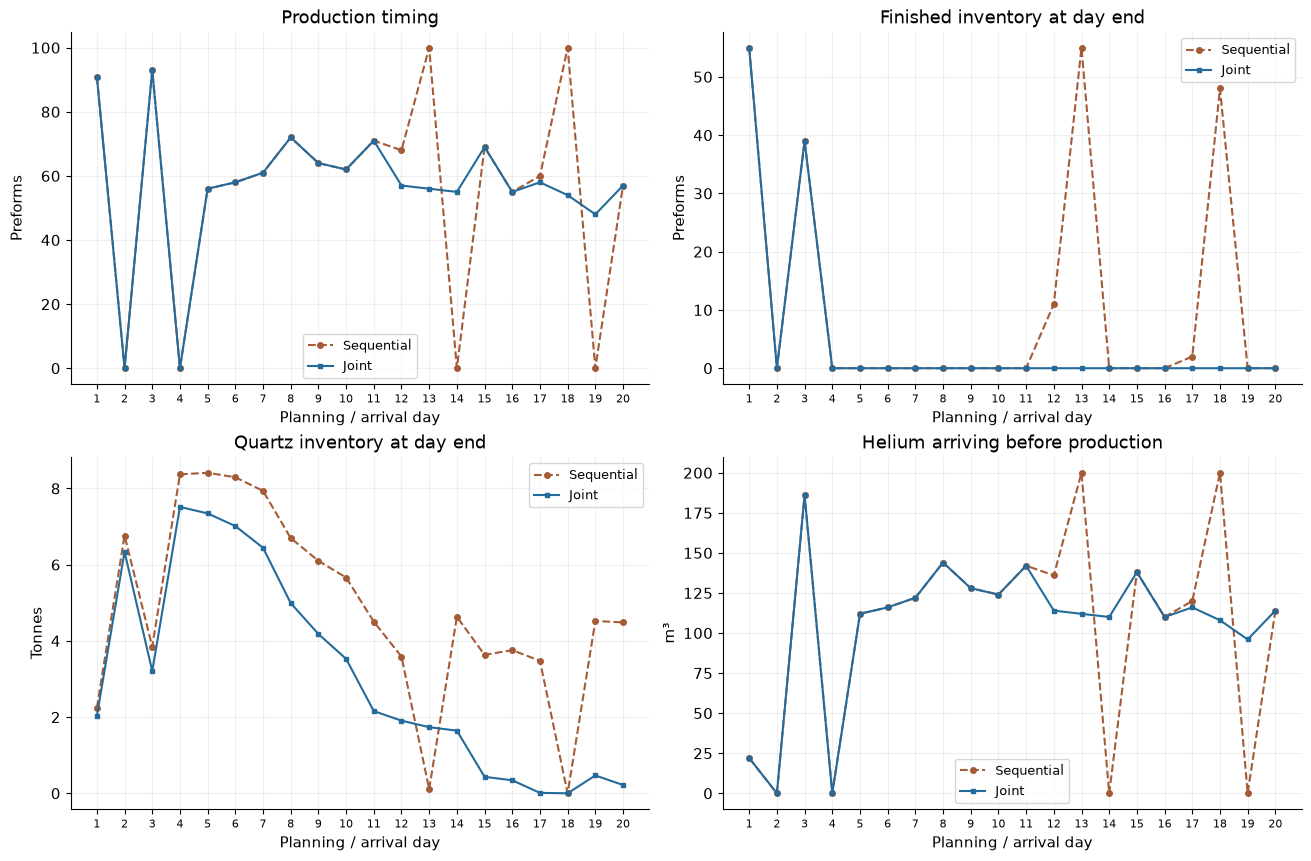

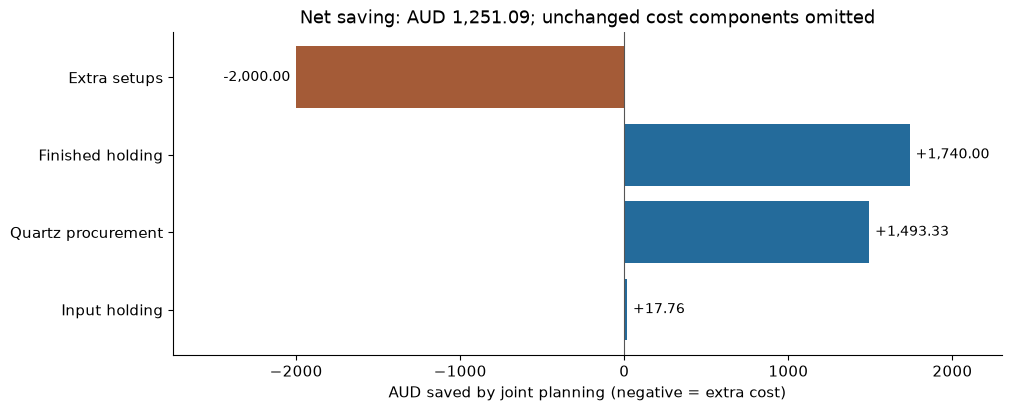

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), layout="constrained")
series = [("Production", "Preforms", "Production timing"),
          ("Finished end", "Preforms", "Finished inventory at day end"),
          ("Quartz end (t)", "Tonnes", "Quartz inventory at day end"),
          ("Helium arrival (m3)", "m³", "Helium arriving before production")]
for ax, (column, unit, title) in zip(axes.flat, series):
    ax.plot(DAYS, seq_plan[column], "o--", color=SEQ_COLOR, markersize=4, label="Sequential")
    ax.plot(DAYS, joint_plan[column], "s-", color=JOINT_COLOR, markersize=3, label="Joint")
    ax.set(title=title, xlabel="Planning / arrival day", ylabel=unit, xticks=DAYS)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
fig.savefig(OUT / "sequential_joint_operations.png", dpi=180, bbox_inches="tight")
plt.show()

components = ["Extra setups", "Finished holding", "Quartz procurement", "Input holding"]
contributions = [seq_costs["Setup"] - joint_costs["Setup"],
    seq_costs["Finished holding"] - joint_costs["Finished holding"],
    seq_costs["Quartz procurement"] - joint_costs["Quartz procurement"],
    sum(seq_costs[k] - joint_costs[k] for k in ["Quartz holding", "Helium holding"])]
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.barh(components, contributions, color=[SEQ_COLOR if v < 0 else JOINT_COLOR for v in contributions])
ax.axvline(0, color="#555555", linewidth=.8)
for i, value in enumerate(contributions):
    ax.text(value + (35 if value >= 0 else -35), i, f"{value:+,.2f}", va="center",
            ha="left" if value >= 0 else "right", fontsize=10)
ax.set(xlim=(-2750, 2300), xlabel="AUD saved by joint planning (negative = extra cost)",
       title=f"Net saving: AUD {saving:,.2f}; unchanged cost components omitted")
ax.invert_yaxis()
fig.savefig(OUT / "cost_saving_drivers.png", dpi=180, bbox_inches="tight")
plt.show()

### Why the plans differ

The joint plan uses **18 setups**, compared with **16** sequentially. The sequential plan produces 68 and 100 units on Days 12–13, leaving 11 and 55 units in inventory. The joint plan instead produces 57 and 56 units on those days, then opens an extra setup on Day 14 to produce 55 units. It also replaces the sequential batches of 60 and 100 units on Days 17–18 with 58 and 54 units, then produces 48 units on Day 19. These changes reduce finished inventory from **210 to 94 preform-days**. Both plans meet demand, avoid backorders and finish with no preform stock.

The extra setups add **AUD 2,000**, while lower finished-goods holding saves **AUD 1,740**. The constant quartz delivery falls from **4.522222 to 4.308889 tonnes per day**, reducing total quartz purchases from **90.444 to 86.178 tonnes**. Quartz procurement falls by **AUD 1,493.33**, and input holding by **AUD 17.76**. Ending quartz inventory falls from **4.484 to 0.218 tonnes**; the joint plan has only **0.011 tonnes** at the end of Day 17 and none at the end of Day 18.

Helium purchases remain **2,114 m³ (AUD 1,057,000)** in both plans, but the arrival schedule changes with production. Arrivals on Days 12–14 change from **136/200/0** to **114/112/110 m³**, and on Days 17–19 from **120/200/0** to **116/108/96 m³**. Each order is placed one day before arrival, and both plans end every day with zero helium inventory.

Overall, joint optimisation saves **AUD 1,251.09 (about 0.11%)**. The saving is modest because helium procurement dominates total cost and does not change; lower finished-goods and quartz costs more than offset the two additional setups.


## 3(d) Recommendation for ZORA — 4 marks

For this 20-day horizon, the joint model is practical to solve and gives the lower-cost plan. Sequential planning solves production first and supply second, which is easier to run when production is already committed. As the horizon, product range or supplier constraints grow, the joint model will require more computation because it couples setup, production, inventory and procurement decisions.

Both approaches depend on accurate demand, inventory, capacity, cost and material-use data. Joint planning also depends on production and procurement teams using the same current information, including supplier lead times, before they make decisions. Its recommendations can take more explanation than the sequential hand-off, so managers should review the daily schedule alongside the cost breakdown: here, two additional setups reduce finished stock and the fixed quartz delivery rate, while helium purchases stay unchanged.

ZORA should use joint optimisation as its planning benchmark when those data and coordination are available. The saving is **AUD 1,251.09 per 20-day horizon**, so supplier reliability and implementation costs matter. The plan leaves only **0.011 tonnes of quartz after Day 17**, reaches zero after Day 18, and relies on next-day helium deliveries. It also requires two extra setup days. ZORA should confirm supplier and staffing capacity, then add any required safety stock or contingency supply to the model and re-solve before using the schedule. Sequential planning remains practical when production cannot be changed or supply information is not reliable enough for an integrated plan.
